In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import starbars
import scipy.stats as stats

In [2]:
dai = pd.read_json("../features/ai_images.json")
dai["type"] = "ai"
dai

,image,niqe,color_fulness,tone,blur,saturation,fft,si,contrast,noise,dominant_color,cpbd,blur_stength,type
0,../prediction/ai_images/p01_9a13178e3ee6607de6...,19.122204,138.946248,0.946140,64623.533663,37.764688,51547.434679,0.306161,89.321414,0.769377,"[18, 13, 19]",0.949622,0.407428,ai
1,../prediction/ai_images/p02_39fff262c8e5bfc859...,18.620085,157.931652,0.291475,22635.508011,32.424165,44628.621797,0.192353,82.658443,0.782603,"[5, 7, 8]",0.987317,0.261441,ai
2,../prediction/ai_images/p03_719f3a060006758ae0...,17.026855,163.721937,0.632829,90741.914968,48.891330,50816.285759,0.374782,92.695028,0.710414,"[57, 58, 40]",0.966000,0.293755,ai
3,../prediction/ai_images/p04_aed059c4f0f6ee575d...,19.539799,133.427117,0.776861,37067.466852,59.989867,45955.651959,0.250006,60.652970,0.553758,"[16, 8, 8]",0.841424,0.600327,ai
4,../prediction/ai_images/p05_100b0a2e31508d9e3b...,18.966452,151.474763,0.901138,52486.140634,38.296822,45936.570512,0.295512,92.947957,0.911697,"[27, 26, 34]",0.542342,0.437628,ai
5,../prediction/ai_images/p06_37dd32efae23f46a9e...,18.984814,164.266564,0.828852,34734.173784,36.063187,49514.002466,0.273692,92.969870,1.216732,"[27, 31, 35]",0.963054,0.426107,ai
6,../prediction/ai_images/p07_bb85ea499ebb266903...,19.081577,104.179231,0.758002,66536.397072,37.073761,49608.332151,0.304554,94.579786,0.329269,"[56, 42, 82]",0.986742,0.320982,ai
7,../prediction/ai_images/p08_190876a2d9ff6ee337...,19.482578,98.231967,0.918086,112242.294158,26.632663,52468.691399,0.364352,81.462040,0.730807,"[16, 14, 13]",0.873611,0.408877,ai
8,../prediction/ai_images/p09_baebb8982088d49be1...,17.505526,148.138988,0.805881,118895.350178,39.122778,51182.473777,0.402302,65.407748,0.934308,"[5, 4, 3]",0.893519,0.376180,ai
9,../prediction/ai_images/p10_5e9da55d2507dd1d32...,18.643507,155.535905,0.810934,43324.731177,45.984275,46421.433832,0.307601,87.623187,0.644797,"[31, 38, 43]",0.647727,0.440215,ai


In [3]:
dreal = pd.read_json("../features/real_images.json")
dreal["type"] = "real"
dreal

,image,niqe,color_fulness,tone,blur,saturation,fft,si,contrast,noise,dominant_color,cpbd,blur_stength,type
0,../prediction/real_images/p01.png,17.820894,156.961812,0.769432,120846.908109,18.075198,50352.384690,0.405106,88.104630,2.695334e+00,"[169, 169, 161]",0.978818,0.250758,real
1,../prediction/real_images/p02.png,17.439297,157.726978,0.408912,24952.267096,7.471986,47124.563310,0.256955,87.495303,7.843060e-01,"[206, 210, 211]",0.925690,0.383379,real
2,../prediction/real_images/p03.png,18.063910,161.148116,0.569386,8377.007216,21.409056,43955.605897,0.229395,93.381672,6.133157e-01,"[21, 28, 26]",1.000000,0.339120,real
3,../prediction/real_images/p04.png,20.275587,93.249316,0.260458,10923.179498,27.178650,42688.351204,0.187052,83.302183,6.034160e-01,"[42, 33, 29]",0.966258,0.398216,real
4,../prediction/real_images/p05.png,19.216234,153.733237,0.995513,139536.916595,21.761632,50749.955282,0.391819,92.004332,7.330248e-01,"[249, 251, 251]",0.946734,0.340551,real
5,../prediction/real_images/p06.png,19.648834,88.525819,0.645049,5242.701604,24.763160,40564.152297,0.156388,86.095162,6.502619e-01,"[24, 22, 18]",0.173913,0.399570,real
6,../prediction/real_images/p07.png,19.965033,131.269444,0.321687,13893.265171,18.244775,41469.260997,0.184505,95.173855,6.855847e-01,"[226, 226, 226]",0.862500,0.424302,real
7,../prediction/real_images/p08.png,19.681498,130.668508,0.610833,17952.357319,36.197468,42000.607241,0.206926,92.870866,8.256875e-01,"[69, 52, 28]",0.758772,0.452260,real
8,../prediction/real_images/p09.png,18.378262,143.193240,0.541459,10435.362417,20.387007,40769.779509,0.190693,90.885505,3.601566e-01,"[47, 45, 32]",0.923977,0.466117,real
9,../prediction/real_images/p10.png,20.859371,100.525831,0.502286,13386.847845,64.638729,43028.996341,0.193774,80.945648,7.473598e-01,"[39, 10, 11]",0.952294,0.280169,real


In [4]:
df = pd.concat([dai, dreal], ignore_index=True)
df.columns
df = df[df.columns.difference(['dominant_color'])]

# min max norm
for col in df.columns.difference(["type", "image"]):
    df[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())

df

,blur,blur_stength,color_fulness,contrast,cpbd,fft,image,niqe,noise,saturation,si,tone,type
0,0.157930,0.494516,0.713110,0.842411,0.949622,0.657012,../prediction/ai_images/p01_9a13178e3ee6607de6...,0.473978,0.268571,0.366296,0.471074,0.948159,ai
1,0.054920,0.114417,0.840435,0.691695,0.987317,0.380302,../prediction/ai_images/p02_39fff262c8e5bfc859...,0.367152,0.273188,0.302081,0.278351,0.260778,ai
2,0.222006,0.198551,0.879267,0.918722,0.966000,0.627771,../prediction/ai_images/p03_719f3a060006758ae0...,0.028194,0.247989,0.500084,0.587277,0.619190,ai
3,0.090326,0.996756,0.676096,0.193933,0.841424,0.433375,../prediction/ai_images/p04_aed059c4f0f6ee575d...,0.562820,0.193304,0.633535,0.375981,0.770421,ai
4,0.128153,0.573144,0.797132,0.924443,0.542342,0.432612,../prediction/ai_images/p05_100b0a2e31508d9e3b...,0.440841,0.318252,0.372695,0.453041,0.900908,ai
...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,0.109209,0.024750,0.873828,0.722343,0.993333,0.628131,../prediction/real_images/p50.png,0.002764,0.156050,0.049569,0.589272,0.036118,real
104,0.011377,0.215706,0.709080,0.669391,0.970149,0.211754,../prediction/real_images/p51.png,0.591983,0.361381,0.213624,0.174492,0.242087,real
105,0.020322,0.462520,0.180511,0.933466,0.817568,0.229986,../prediction/real_images/p52.png,0.698212,0.107821,0.410071,0.169485,0.803726,real
106,0.013625,0.535021,0.683375,0.689498,0.897297,0.214189,../prediction/real_images/p53.png,0.746409,0.107821,0.032887,0.201301,0.607739,real


In [5]:
df_long = pd.melt(
    df, 
    id_vars=['image', 'type'], 
    value_vars=['niqe', 'color_fulness', 'tone', 'blur', 'saturation', 'fft', 'si', 'contrast', 'noise', 'cpbd', 'blur_stength'],
    var_name='metric', value_name='value'
)
df_long

,image,type,metric,value
0,../prediction/ai_images/p01_9a13178e3ee6607de6...,ai,niqe,0.473978
1,../prediction/ai_images/p02_39fff262c8e5bfc859...,ai,niqe,0.367152
2,../prediction/ai_images/p03_719f3a060006758ae0...,ai,niqe,0.028194
3,../prediction/ai_images/p04_aed059c4f0f6ee575d...,ai,niqe,0.562820
4,../prediction/ai_images/p05_100b0a2e31508d9e3b...,ai,niqe,0.440841
...,...,...,...,...
1183,../prediction/real_images/p50.png,real,blur_stength,0.024750
1184,../prediction/real_images/p51.png,real,blur_stength,0.215706
1185,../prediction/real_images/p52.png,real,blur_stength,0.462520
1186,../prediction/real_images/p53.png,real,blur_stength,0.535021


<Axes: xlabel='value', ylabel='metric'>

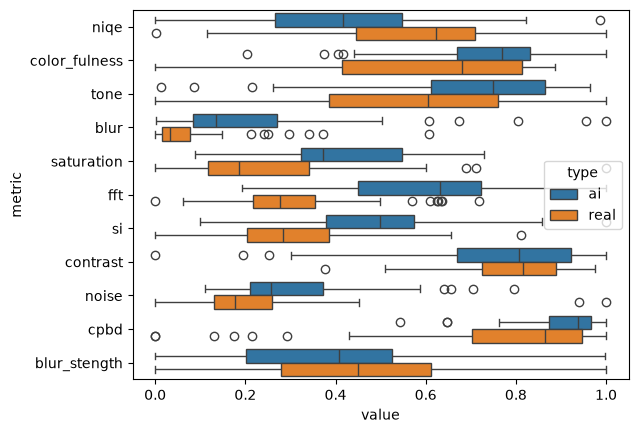

In [6]:
sns.boxplot(x="value", y="metric", data=df_long, hue="type")
# well nothing to gain here

In [7]:
# check clip embeddings
import glob
import json
import os

def read_json(x):
    with open(x) as xfp:
        j = json.load(xfp)
    return j

def read_embeddings(folder, name):
    df = pd.DataFrame(map(read_json, glob.glob(f"{folder}/*.json")))
    df = df.sort_values(by="image")
    df["type"] = name
    df["pid"] = df["image"].apply(lambda x: os.path.splitext(os.path.basename(x))[0].split("_")[0])
    return df

dreal = read_embeddings("../embeddings/embeddings_real/", "real")
dreal

,features,image,type,pid
9,"[[0.02900710143148899, 0.13359075784683228, -0...",real_images/p01.png,real,p01
30,"[[0.011779362335801125, 0.12826098501682281, -...",real_images/p02.png,real,p02
22,"[[0.01843252405524254, 0.1189453974366188, -0....",real_images/p03.png,real,p03
37,"[[-0.021975914016366005, 0.15121637284755707, ...",real_images/p04.png,real,p04
29,"[[-0.015230558812618256, 0.05257415398955345, ...",real_images/p05.png,real,p05
13,"[[0.07652080059051514, 0.21351362764835358, 0....",real_images/p06.png,real,p06
4,"[[0.012075047940015793, 0.21087487041950226, -...",real_images/p07.png,real,p07
7,"[[0.03309592604637146, 0.2866405248641968, 0.0...",real_images/p08.png,real,p08
31,"[[0.06768682599067688, 0.12355656921863556, -0...",real_images/p09.png,real,p09
41,"[[0.033166754990816116, 0.0888773575425148, -0...",real_images/p10.png,real,p10


In [8]:
dai = read_embeddings("../embeddings/embeddings_ai/", "ai")
dai

,features,image,type,pid
50,"[[0.06565427780151367, 0.11091388016939163, -0...",ai_images/p01_9a13178e3ee6607de66da8a13e337e82...,ai,p01
29,"[[0.012637903913855553, 0.12414640933275223, -...",ai_images/p02_39fff262c8e5bfc8592fba1051bd982f...,ai,p02
49,"[[0.04348636791110039, 0.13849151134490967, -0...",ai_images/p03_719f3a060006758ae04ac9bb8aa9208a...,ai,p03
11,"[[0.020400766283273697, 0.13843859732151031, 0...",ai_images/p04_aed059c4f0f6ee575d0ddeff96b05030...,ai,p04
31,"[[0.027281224727630615, 0.06459000706672668, -...",ai_images/p05_100b0a2e31508d9e3b9a30a52d0327fa...,ai,p05
7,"[[0.0644644945859909, 0.2153058648109436, -0.0...",ai_images/p06_37dd32efae23f46a9e466b97757355bb...,ai,p06
21,"[[0.09740544855594635, 0.029583759605884552, -...",ai_images/p07_bb85ea499ebb2669034e2ffc0559dbe4...,ai,p07
5,"[[0.018839411437511444, 0.23152856528759003, -...",ai_images/p08_190876a2d9ff6ee337b9cb58672d6b77...,ai,p08
41,"[[0.053157877177000046, 0.10853388905525208, -...",ai_images/p09_baebb8982088d49be19a8873f68b662b...,ai,p09
20,"[[-0.02726416476070881, 0.00966875720769167, -...",ai_images/p10_5e9da55d2507dd1d3298bdb653e74874...,ai,p10


In [9]:
import sklearn.metrics.pairwise

dm = pd.merge(dai, dreal, left_on="pid", right_on="pid", suffixes=("_ai", "_real"))
dm = dm[["features_ai", "features_real", "pid"]]
def measure_cos_sim(real, ai):
    real = np.array(real)
    ai = np.array(ai)
    return sklearn.metrics.pairwise.cosine_similarity(real, ai).flatten()[0]

def measure_rmse(real, ai):
    real = np.array(real).flatten()
    ai = np.array(ai).flatten()
    return sklearn.metrics.root_mean_squared_error(real, ai)#[0]

def measure_pearson(real, ai):
    real = np.array(real).flatten()
    ai = np.array(ai).flatten()
    return np.corrcoef(real, ai)[0][1]


dm["cos_sim"] = dm.apply(lambda x: measure_cos_sim(x["features_real"], x["features_ai"]), axis=1)
dm["rmse"] = dm.apply(lambda x: measure_rmse(x["features_real"], x["features_ai"]), axis=1)
dm["pearson"] = dm.apply(lambda x: measure_pearson(x["features_real"], x["features_ai"]), axis=1)
dm

,features_ai,features_real,pid,cos_sim,rmse,pearson
0,"[[0.06565427780151367, 0.11091388016939163, -0...","[[0.02900710143148899, 0.13359075784683228, -0...",p01,0.572693,0.040855,0.572089
1,"[[0.012637903913855553, 0.12414640933275223, -...","[[0.011779362335801125, 0.12826098501682281, -...",p02,0.698946,0.034293,0.699083
2,"[[0.04348636791110039, 0.13849151134490967, -0...","[[0.01843252405524254, 0.1189453974366188, -0....",p03,0.684051,0.035131,0.683807
3,"[[0.020400766283273697, 0.13843859732151031, 0...","[[-0.021975914016366005, 0.15121637284755707, ...",p04,0.701929,0.034122,0.702194
4,"[[0.027281224727630615, 0.06459000706672668, -...","[[-0.015230558812618256, 0.05257415398955345, ...",p05,0.636720,0.037670,0.636982
5,"[[0.0644644945859909, 0.2153058648109436, -0.0...","[[0.07652080059051514, 0.21351362764835358, 0....",p06,0.775585,0.029608,0.774323
6,"[[0.09740544855594635, 0.029583759605884552, -...","[[0.012075047940015793, 0.21087487041950226, -...",p07,0.549979,0.041927,0.549914
7,"[[0.018839411437511444, 0.23152856528759003, -...","[[0.03309592604637146, 0.2866405248641968, 0.0...",p08,0.585149,0.040256,0.585213
8,"[[0.053157877177000046, 0.10853388905525208, -...","[[0.06768682599067688, 0.12355656921863556, -0...",p09,0.652741,0.036830,0.653710
9,"[[-0.02726416476070881, 0.00966875720769167, -...","[[0.033166754990816116, 0.0888773575425148, -0...",p10,0.518684,0.043361,0.519112


In [10]:
# reference value:

lower_ai = []

for y in dm["pid"].values:
    for x in filter(lambda x: x!= y, dm["pid"].values):
        lower_ai.append(
            measure_cos_sim(dm[dm["pid"] == y]["features_ai"].values[0], dm[dm["pid"] == x]["features_ai"].values[0])
        )

lower_real = []

for y in dm["pid"].values:
    for x in filter(lambda x: x!= y, dm["pid"].values):
        lower_real.append(
            measure_cos_sim(dm[dm["pid"] == y]["features_real"].values[0], dm[dm["pid"] == x]["features_real"].values[0])
        )

In [11]:
np.array(lower_ai).mean()

np.float64(0.3979429596656041)

In [12]:
dlower_ai = pd.DataFrame({"value": lower_ai})
dlower_ai["metric"] = "cos_sim(AI)"
dlower_ai

,value,metric
0,0.352747,cos_sim(AI)
1,0.349321,cos_sim(AI)
2,0.380320,cos_sim(AI)
3,0.620776,cos_sim(AI)
4,0.392665,cos_sim(AI)
...,...,...
2857,0.461982,cos_sim(AI)
2858,0.459365,cos_sim(AI)
2859,0.450279,cos_sim(AI)
2860,0.391017,cos_sim(AI)


In [13]:
np.array(lower_real).mean()

np.float64(0.3665743145654871)

In [14]:
dlower_real = pd.DataFrame({"value": lower_real})
dlower_real["metric"] = "cos_sim(real)"
dlower_real

,value,metric
0,0.378378,cos_sim(real)
1,0.419539,cos_sim(real)
2,0.348059,cos_sim(real)
3,0.377863,cos_sim(real)
4,0.422474,cos_sim(real)
...,...,...
2857,0.565155,cos_sim(real)
2858,0.531233,cos_sim(real)
2859,0.543491,cos_sim(real)
2860,0.376562,cos_sim(real)


In [15]:
dm_long = pd.melt(
    dm, 
    id_vars=['pid'], 
    value_vars=['pearson', 'rmse', 'cos_sim'],
    var_name='metric', value_name='value'
)
dm_long

,pid,metric,value
0,p01,pearson,0.572089
1,p02,pearson,0.699083
2,p03,pearson,0.683807
3,p04,pearson,0.702194
4,p05,pearson,0.636982
...,...,...,...
157,p50,cos_sim,0.796777
158,p51,cos_sim,0.423051
159,p52,cos_sim,0.784246
160,p53,cos_sim,0.412938


In [16]:
dm.sort_values(by="pearson").head(5)

,features_ai,features_real,pid,cos_sim,rmse,pearson
16,"[[0.013755681924521923, 0.1516590118408203, -0...","[[0.003422150854021311, 0.012415779754519463, ...",p17,0.381044,0.049171,0.381134
52,"[[0.026331143453717232, 0.11430279910564423, -...","[[-0.015067782253026962, 0.12791696190834045, ...",p53,0.412938,0.047887,0.412800
34,"[[0.01637742854654789, 0.14716847240924835, -0...","[[0.04786410555243492, 0.23784242570400238, 0....",p35,0.415827,0.047770,0.416361
50,"[[-0.0068007404915988445, 0.18892960250377655,...","[[0.009478539228439331, 0.18801087141036987, -...",p51,0.423051,0.047473,0.422983
26,"[[0.029018152505159378, 0.09242242574691772, 0...","[[0.0057985857129096985, 0.10980585217475891, ...",p27,0.462515,0.045821,0.463375


In [17]:
values = dm_long[dm_long["metric"] == "cos_sim"][["metric", "value"]].copy()
values["metric"] = "cos_sim(AI, real)"
values = pd.concat([values, dlower_real, dlower_ai], ignore_index=True)

values

,metric,value
0,"cos_sim(AI, real)",0.572693
1,"cos_sim(AI, real)",0.698946
2,"cos_sim(AI, real)",0.684051
3,"cos_sim(AI, real)",0.701929
4,"cos_sim(AI, real)",0.636720
...,...,...
5773,cos_sim(AI),0.461982
5774,cos_sim(AI),0.459365
5775,cos_sim(AI),0.450279
5776,cos_sim(AI),0.391017


In [18]:
set(values["metric"].values)

{'cos_sim(AI)', 'cos_sim(AI, real)', 'cos_sim(real)'}

-3.0 0.03
-3.0 0.03


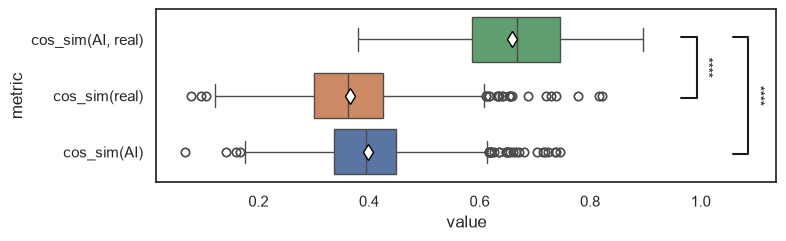

In [19]:
sns.set(rc={'figure.figsize':(8,3*1.5 / 2)})
sns.set_style("white")

ax = sns.boxplot(
    x="value", y="metric", data=values, hue="metric", hue_order=['cos_sim(AI)',  'cos_sim(real)', 'cos_sim(AI, real)'],
    showmeans=True, meanprops={'marker':'d','markerfacecolor':'white','markeredgecolor':'black','markersize':'8'}
)

annotations = []
t_stat, p_value = stats.ttest_ind(
    values[values["metric"] == "cos_sim(AI, real)"]["value"], 
    values[values["metric"] == "cos_sim(real)"]["value"],
)
annotations.append(
    ("cos_sim(AI, real)","cos_sim(real)", p_value)
)

t_stat, p_value = stats.ttest_ind(
    values[values["metric"] == "cos_sim(AI, real)"]["value"], 
    values[values["metric"] == "cos_sim(AI)"]["value"],
)
annotations.append(
    ("cos_sim(AI, real)","cos_sim(AI)", p_value)
)



starbars.draw_annotation(annotations, mode="horizontal")

ax.get_figure().savefig("cos_sims.pdf", bbox_inches="tight")



In [20]:
dall = pd.concat([dai, dreal], ignore_index=True)
arrays = dall["features"].apply(lambda x: x[0]).values


matrix = np.vstack(arrays) 
matrix.shape

(108, 512)

In [21]:
from sklearn.manifold import TSNE
import plotly.express as px
# pip install plotly kaleido

_embedded = TSNE(n_components=2, learning_rate='auto', init='random', random_state=412, perplexity=3).fit_transform(matrix)

fig = px.scatter(
    x=_embedded[:,0], y=_embedded[:,1], hover_data=[dall["pid"].values], color=dall["pid"].values, symbol=dall["type"].values,  width=600, height=600)
fig.show()
#fig.write_image("tsne.pdf")

In [22]:
dall["e_x"] = _embedded[:,0]
dall["e_y"] = _embedded[:,1]

dall

,features,image,type,pid,e_x,e_y
0,"[[0.06565427780151367, 0.11091388016939163, -0...",ai_images/p01_9a13178e3ee6607de66da8a13e337e82...,ai,p01,-21.051123,2.575747
1,"[[0.012637903913855553, 0.12414640933275223, -...",ai_images/p02_39fff262c8e5bfc8592fba1051bd982f...,ai,p02,-32.232697,-34.262707
2,"[[0.04348636791110039, 0.13849151134490967, -0...",ai_images/p03_719f3a060006758ae04ac9bb8aa9208a...,ai,p03,-16.056765,-44.532780
3,"[[0.020400766283273697, 0.13843859732151031, 0...",ai_images/p04_aed059c4f0f6ee575d0ddeff96b05030...,ai,p04,18.462929,10.910824
4,"[[0.027281224727630615, 0.06459000706672668, -...",ai_images/p05_100b0a2e31508d9e3b9a30a52d0327fa...,ai,p05,-18.481770,2.166169
...,...,...,...,...,...,...
103,"[[-0.029315311461687088, 0.23461005091667175, ...",real_images/p50.png,real,p50,3.337207,22.853813
104,"[[0.009478539228439331, 0.18801087141036987, -...",real_images/p51.png,real,p51,-20.573299,27.028069
105,"[[-0.027863414958119392, 0.2293650209903717, 0...",real_images/p52.png,real,p52,-13.168594,45.476006
106,"[[-0.015067782253026962, 0.12791696190834045, ...",real_images/p53.png,real,p53,2.511462,39.491871


In [23]:
dmmm = pd.merge(
    dall[dall["type"] == "ai"], 
    dall[dall["type"] == "real"], left_on="pid", right_on="pid", suffixes=("_ai", "_real"))

def calc_embedding_distance(x):
    return np.sqrt((x["e_x_ai"] - x["e_x_real"]) ** 2 + (x["e_y_ai"] - x["e_y_real"]) ** 2)
    
dmmm["dist"] = dmmm.apply(calc_embedding_distance, axis=1)
dmmm[["pid", "dist"]].sort_values(by="dist")

,pid,dist
51,p52,1.007968
43,p44,1.008489
18,p19,1.012810
12,p13,1.013096
42,p43,1.016663
45,p46,1.022123
53,p54,1.024151
17,p18,1.026343
24,p25,1.031917
32,p33,1.036615


In [24]:
worst_prompts = dmmm[["pid", "dist"]].sort_values(by="dist", ascending=False).head(6)
worst_prompts

,pid,dist
50,p51,65.048127
34,p35,50.060557
9,p10,34.111389
16,p17,22.738537
46,p47,15.222750
52,p53,10.415056


p51
p35
p10
p17
p47
p53


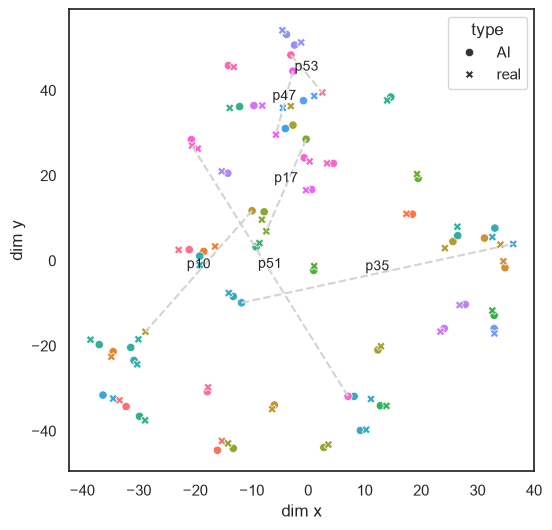

In [29]:
import matplotlib.pyplot as plt

sns.set(rc={'figure.figsize':(6,6)})
sns.set_style("white")

ax = sns.scatterplot(
    x="e_x",
    y="e_y",
    hue="pid",
    style="type",
    data=dall,
    legend="brief"
)
# dall["pid"].values



# Get existing legend handles and labels
handles, labels = ax.get_legend_handles_labels()

# Filter out hue-related entries (e.g., based on the 'event' labels)
# Assuming 'event' labels are distinct from 'region' labels
filtered_handles = []
filtered_labels = []
for h, l in zip(handles, labels):
    if l in dall["type"].unique(): 
        filtered_handles.append(h)
        filtered_labels.append(l.replace("ai", "AI"))

# Remove the default legend
ax.get_legend().remove()

# Create a new legend with only the style entries
ax.legend(filtered_handles, filtered_labels, title="type")


ax.set_xlabel("dim x")
ax.set_ylabel("dim y")
for p in worst_prompts["pid"]:
    print(p)
    x_vals = dall[dall["pid"] == p]["e_x"].values
    y_vals = dall[dall["pid"] == p]["e_y"].values

    ax.plot(
        x_vals, 
        y_vals, 
        color='lightgray', 
        linestyle='--', 
        label=p
    )
    #ax.text(x_vals.mean(), y_vals.mean(), p, fontsize=11, color='gray')
    
    ax.annotate(
        p, 
        xy=(x_vals.mean(), y_vals.mean()), 
        xytext=(0,0), 
        textcoords='offset points', ha='center', va='bottom',
        size=10
        #bbox=dict(boxstyle='round,pad=0.2', fc='yellow', alpha=0.3),
        #arrowprops=dict(arrowstyle='-', connectionstyle='arc3,rad=0.5', color='red')
    )
            

plt.show()
ax.get_figure().savefig("tsne.pdf", bbox_inches="tight")



In [ ]:
sns.histplot(dmmm["dist"])

In [ ]:
# check iqa features

# ai part

diqa_ai = pd.read_json("ai_images_iqa.json")
diqa_ai["pid"] = diqa_ai.index.values
diqa_ai["pid"] = diqa_ai["pid"].apply(lambda x: os.path.basename(x).split("_")[0])
diqa_ai = diqa_ai[diqa_ai["pid"] != "mean"].reset_index()
diqa_ai = diqa_ai[diqa_ai.columns.difference(["index"])]
diqa_ai["type"] = "ai"
diqa_ai

In [ ]:
# real images

diqa_real = pd.read_json("real_images_iqa.json")
diqa_real["pid"] = diqa_real.index.values
diqa_real["pid"] = diqa_real["pid"].apply(
    lambda x: 
    os.path.splitext(os.path.basename(x).split("_")[0])[0]
)

diqa_real = diqa_real[diqa_real["pid"] != "mean"].reset_index()
diqa_real = diqa_real[diqa_real.columns.difference(["index"])]
diqa_real["type"] = "real"
diqa_real

In [ ]:
diqa = pd.concat([diqa_ai, diqa_real], ignore_index=True)
diqa

In [ ]:
sns.boxplot(x="qualiclip+", y="type", hue="type", data=diqa)

In [ ]:
diqa_long = pd.melt(
    diqa, 
    id_vars=['pid', 'type'], 
    value_vars=diqa.columns.difference(["pid", "type"]),
    var_name='iqa_model', value_name='value'
)
diqa_long

In [ ]:
#sns.boxplot(x="value", row="metric", hue="type", data=diqa_long)
sns.catplot(
    data=diqa_long, 
    x="value", 
    kind="box", 
    col="iqa_model", 
    y="type",
    hue="type",
    sharey=True, sharex=False
)
